# IMPORTING LIBRARIES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# LOAD THE DATA 

In [2]:
df = pd.read_excel("Online Retail.xlsx")                     # Load the Excel dataset into a DataFrame

In [3]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [4]:
df.head()                                 # display first 5 rows

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


# EXPLORE THE DATA 

In [6]:
df.shape                                 # Show the number of rows and columns

(541909, 8)

In [11]:
df.columns.tolist()                     # Show all column names

['InvoiceNo',
 'StockCode',
 'Description',
 'Quantity',
 'InvoiceDate',
 'UnitPrice',
 'CustomerID',
 'Country']

In [13]:
df.dtypes                               # Show the data type of every column

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

In [15]:
df.info()                              # Display general information about the dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [17]:
df.describe()                         # Display summary statistics for numerical columns

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [19]:
df.describe.(include="all")                 # Display summary statistics for all columns

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909.0,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900.0,4070,4223,NaN,NaN,NaN,NaN,38
top,573585.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1114.0,2313,2369,NaN,NaN,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570,NaN
min,NaN,NaN,NaN,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,2011-03-28 11:34:00,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,2011-07-19 17:17:00,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,2011-10-19 11:27:00,4.130000,16791.000000,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,NaN


# CHECK MISSING VALUES & DUPLICATE 

In [24]:
missing_counts = df.isnull().sum()                       # Count missing values in each column

In [26]:
missing_counts

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [25]:
print("Missing values in each column:")
display(missing_counts.to_frame(name="Missing Count"))

Missing values in each column:


,Missing Count
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [27]:
missing_percent = (df.isnull().mean() * 100).round(2)  # Calculate the percentage of missing values per column

In [28]:
missing_percent

InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64

In [29]:
print("\nMissing value percentage:")
display(missing_percent.to_frame(name="Missing Percentage"))


Missing value percentage:


,Missing Percentage
InvoiceNo,0.00
StockCode,0.00
Description,0.27
Quantity,0.00
InvoiceDate,0.00
UnitPrice,0.00
CustomerID,24.93
Country,0.00


In [38]:
duplicate_count = df.duplicated().sum()                     # Count completely duplicated rows

print("\nNumber of duplicate rows:", duplicate_count)



Number of duplicate rows: 5268


In [39]:
rows_with_missing = df.isnull().any(axis=1).sum()
                                                                          # Check how many records contain at least one missing value
print("Rows containing missing values:", rows_with_missing)

Rows containing missing values: 135080


# CHECK NUMERICAL DISTRIBUTION VISUALLY 

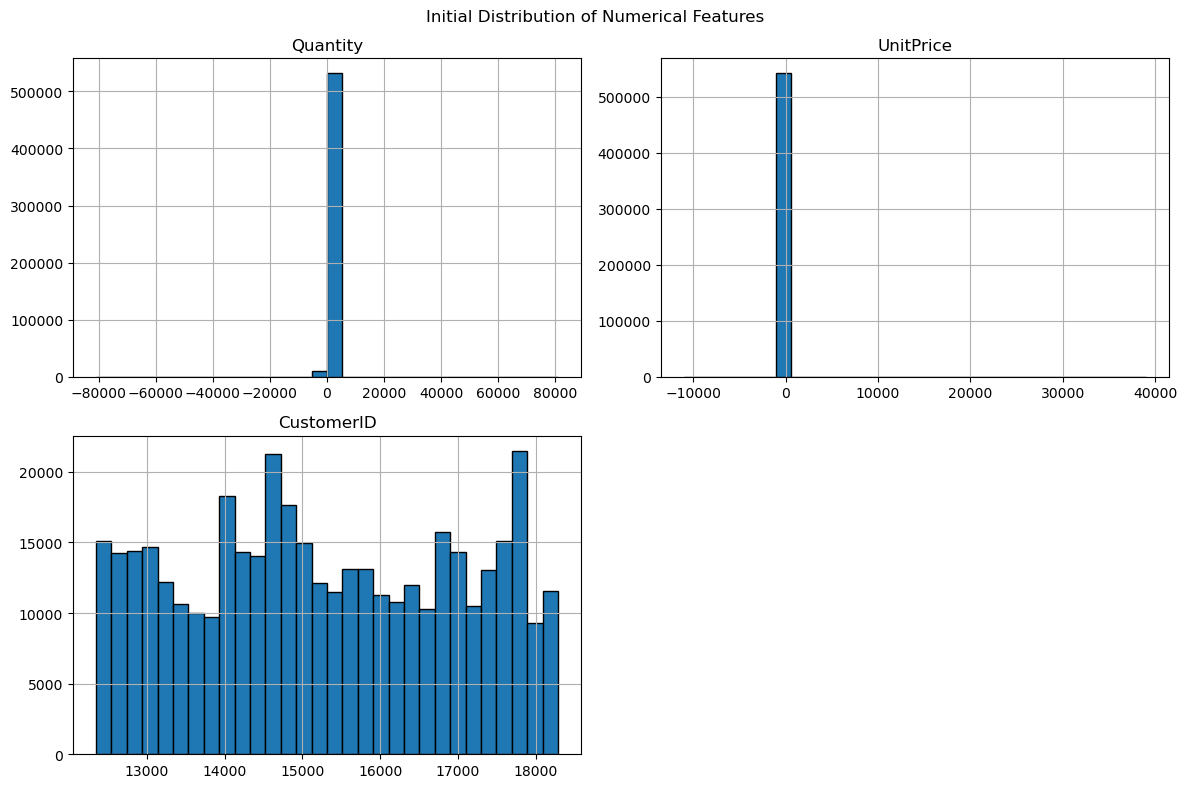

In [41]:

# Select the numerical columns for inspection
numeric_columns = df.select_dtypes(include=np.number).columns

# Create a histogram for each numerical column
df[numeric_columns].hist(
    figsize=(12, 8),
    bins=30,
    edgecolor="black"
)

# Add a title to the complete figure
plt.suptitle("Initial Distribution of Numerical Features")

# Adjust spacing between charts
plt.tight_layout()


# CREATING A SAFE WORKING COPY 

In [45]:

# Make a copy of the original data
df_clean = df.copy()

# Remove leading and trailing spaces from column names
df_clean.columns = df_clean.columns.str.strip()

# Remove leading and trailing spaces from text columns
text_columns = df_clean.select_dtypes(include=["object", "string"]).columns

for col in text_columns:
    # Convert text values to strings where appropriate and strip spaces
    # Preserve missing values instead of converting them into the word "nan"
    df_clean[col] = df_clean[col].map(
        lambda value: value.strip() if isinstance(value, str) else value
    )

# Convert invoice dates into proper datetime values
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

# Convert quantity into numeric values
df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"],
    errors="coerce"
)

# Convert unit price into numeric values
df_clean["UnitPrice"] = pd.to_numeric(
    df_clean["UnitPrice"],
    errors="coerce"
)

# Check the updated data types
print("Updated data types:")
print(df_clean.dtypes)

# Count values that are missing after conversion
print("\nMissing values after type correction:")
display(df_clean.isnull().sum())


Updated data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

Missing values after type correction:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

# REMOVE CONFIRMED DUPLICATE ROWS 

In [46]:

# Count duplicate rows before removal
duplicates_before = df_clean.duplicated().sum()

print("Duplicate rows before cleaning:", duplicates_before)

# Remove exact duplicate rows from the working copy
df_clean = df_clean.drop_duplicates().copy()

# Count duplicate rows after removal
duplicates_after = df_clean.duplicated().sum()

print("Duplicate rows after cleaning:", duplicates_after)

# Calculate how many rows were removed
print("Rows removed:", duplicates_before - duplicates_after)


Duplicate rows before cleaning: 5268
Duplicate rows after cleaning: 0
Rows removed: 5268


# IDENTIFY POTENTIAL INVALID RECORDS 

In [47]:

# Identify records with missing invoice dates
invalid_dates = df_clean["InvoiceDate"].isna()

# Identify transactions with zero or negative quantities
nonpositive_quantity = df_clean["Quantity"] <= 0

# Identify records with zero or negative unit prices
nonpositive_price = df_clean["UnitPrice"] <= 0

# Identify cancelled invoices using the invoice number
cancelled_invoice = (
    df_clean["InvoiceNo"]
    .astype("string")
    .str.upper()
    .str.startswith("C", na=False)
)

# Display the count of each condition
print("Missing or invalid dates:", invalid_dates.sum())
print("Zero or negative quantities:", nonpositive_quantity.sum())
print("Zero or negative prices:", nonpositive_price.sum())
print("Cancelled invoice records:", cancelled_invoice.sum())

# Display a sample of records that need investigation
display(
    df_clean.loc[
        invalid_dates | nonpositive_quantity | nonpositive_price | cancelled_invoice
    ].head(10)
)


Missing or invalid dates: 0
Zero or negative quantities: 10587
Zero or negative prices: 2512
Cancelled invoice records: 9251


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom


# CALULATE SALES VALUE 

In [48]:

# Create a new column representing the value of each transaction line
df_clean["LineValue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# Display a few transaction records and their calculated values
display(
    df_clean[
        ["InvoiceNo", "Quantity", "UnitPrice", "LineValue"]
    ].head()
)


,InvoiceNo,Quantity,UnitPrice,LineValue
0,536365,6,2.55,15.30
1,536365,6,3.39,20.34
2,536365,8,2.75,22.00
3,536365,6,3.39,20.34
4,536365,6,3.39,20.34


# DETECT & INVESTIGATE OUTLIERS 

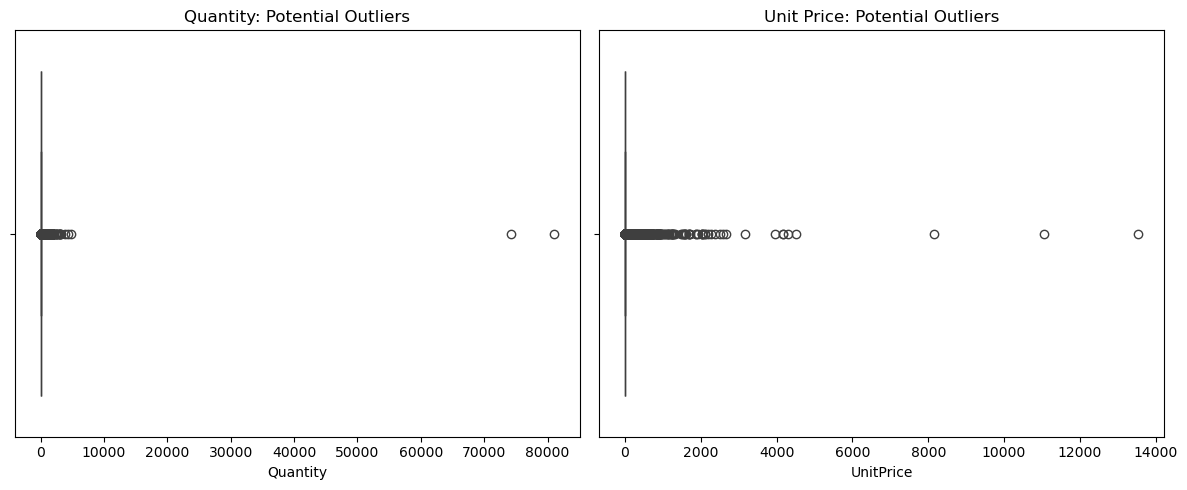

Quantity lower bound: -14.0
Quantity upper bound: 26.0
Potential quantity outliers: 27111


In [49]:

# Examine only positive quantities and positive prices
# to avoid mixing ordinary purchases with returns or invalid prices
positive_transactions = df_clean.loc[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

# Create boxplots to visualize potential outliers
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Boxplot for quantity
sns.boxplot(
    x=positive_transactions["Quantity"],
    ax=axes[0]
)
axes[0].set_title("Quantity: Potential Outliers")

# Boxplot for unit price
sns.boxplot(
    x=positive_transactions["UnitPrice"],
    ax=axes[1]
)
axes[1].set_title("Unit Price: Potential Outliers")

# Improve chart spacing
plt.tight_layout()

# Display both charts
plt.show()

# Calculate the IQR boundaries for quantity
q1 = positive_transactions["Quantity"].quantile(0.25)
q3 = positive_transactions["Quantity"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Count values outside the IQR boundaries
quantity_outliers = (
    (positive_transactions["Quantity"] < lower_bound) |
    (positive_transactions["Quantity"] > upper_bound)
)

print("Quantity lower bound:", lower_bound)
print("Quantity upper bound:", upper_bound)
print("Potential quantity outliers:", quantity_outliers.sum())


# HANDLE MISSING VALUES 

In [50]:

# Start with the cleaned master dataset
df_sales = df_clean.copy()

# Keep records with valid invoice dates
df_sales = df_sales.loc[
    df_sales["InvoiceDate"].notna()
].copy()

# Keep positive quantities and prices for this purchase analysis
# This excludes returns, cancellations with negative quantities,
# and zero or negative prices from this specific subset
df_sales = df_sales.loc[
    (df_sales["Quantity"] > 0) &
    (df_sales["UnitPrice"] > 0)
].copy()

# Recalculate the line value for the selected records
df_sales["LineValue"] = (
    df_sales["Quantity"] * df_sales["UnitPrice"]
)

# Display the number of records remaining
print("Master dataset rows:", len(df_clean))
print("Purchase analysis rows:", len(df_sales))

# Display the first five records
display(df_sales.head())


Master dataset rows: 536641
Purchase analysis rows: 524878


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineValue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


# NORMALIZE NUMERICAL FEATURES [ APPLY STANDARD SCALER ]

In [51]:

# Import StandardScaler from scikit-learn
from sklearn.preprocessing import StandardScaler

# Select the numerical features to scale
scale_columns = ["Quantity", "UnitPrice"]

# Create the scaler object
scaler = StandardScaler()

# Fit the scaler and transform the selected columns
scaled_values = scaler.fit_transform(
    df_sales[scale_columns]
)

# Store the scaled values in a separate DataFrame
df_scaled = pd.DataFrame(
    scaled_values,
    columns=[col + "_scaled" for col in scale_columns],
    index=df_sales.index
)

# Display the original and scaled values together
display(
    pd.concat(
        [
            df_sales[scale_columns].head(),
            df_scaled.head()
        ],
        axis=1
    )
)


,Quantity,UnitPrice,Quantity_scaled,UnitPrice_scaled
0,6,2.55,-0.029541,-0.038029
1,6,3.39,-0.029541,-0.014756
2,8,2.75,-0.016743,-0.032488
3,6,3.39,-0.029541,-0.014756
4,6,3.39,-0.029541,-0.014756


# ENCODE CATEGORICAL VARIABLES WHEN REQUIRED 

In [52]:

# Import OneHotEncoder
from sklearn.preprocessing import OneHotEncoder

# Select a categorical feature for demonstration
country_data = df_sales[["Country"]].fillna("Unknown")

# Create an encoder that ignores categories not seen during fitting
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Learn the categories and encode the country values
country_encoded = encoder.fit_transform(country_data)

# Convert the encoded array into a DataFrame
country_encoded_df = pd.DataFrame(
    country_encoded,
    columns=encoder.get_feature_names_out(["Country"]),
    index=df_sales.index
)

# Display a small sample of the encoded data
display(country_encoded_df.head())


,Country_Australia,Country_Austria,Country_Bahrain,Country_Belgium,Country_Brazil,Country_Canada,Country_Channel Islands,Country_Cyprus,Country_Czech Republic,Country_Denmark,...,Country_RSA,Country_Saudi Arabia,Country_Singapore,Country_Spain,Country_Sweden,Country_Switzerland,Country_USA,Country_United Arab Emirates,Country_United Kingdom,Country_Unspecified
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


# VALIDATE THE PREPARED DATA 

In [53]:

# Check whether exact duplicate rows remain
print("Remaining duplicate rows:", df_clean.duplicated().sum())

# Check missing values in the cleaned master dataset
print("\nMissing values in cleaned master data:")
display(df_clean.isnull().sum().to_frame("Missing Count"))

# Confirm that the invoice date column has datetime type
print("\nInvoiceDate data type:", df_clean["InvoiceDate"].dtype)

# Check for negative and zero prices and quantities
print("\nNon-positive quantities:", (df_clean["Quantity"] <= 0).sum())
print("Non-positive prices:", (df_clean["UnitPrice"] <= 0).sum())

# Validate the purchase-analysis subset
print("\nPurchase subset checks:")
print("All quantities positive:", (df_sales["Quantity"] > 0).all())
print("All prices positive:", (df_sales["UnitPrice"] > 0).all())
print("All dates valid:", df_sales["InvoiceDate"].notna().all())
print("All line values non-negative:", (df_sales["LineValue"] >= 0).all())

# Check the sales calculation
expected_line_value = df_sales["Quantity"] * df_sales["UnitPrice"]

print(
    "Line values calculated correctly:",
    np.allclose(
        df_sales["LineValue"],
        expected_line_value,
        equal_nan=True
    )
)

# Show the final shape of each dataset
print("\nCleaned master shape:", df_clean.shape)
print("Purchase analysis shape:", df_sales.shape)


Remaining duplicate rows: 0

Missing values in cleaned master data:


,Missing Count
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135037
Country,0
LineValue,0



InvoiceDate data type: datetime64[ns]

Non-positive quantities: 10587
Non-positive prices: 2512

Purchase subset checks:
All quantities positive: True
All prices positive: True
All dates valid: True
All line values non-negative: True
Line values calculated correctly: True

Cleaned master shape: (536641, 9)
Purchase analysis shape: (524878, 9)


# SAVE THE PREPARED DATA 

In [54]:

# Save the cleaned master dataset
df_clean.to_csv(
    "online_retail_cleaned_master.csv",
    index=False
)

# Save the positive-purchase analytical subset
df_sales.to_csv(
    "online_retail_purchase_analysis.csv",
    index=False
)

# Save the scaled numerical features separately
df_scaled.to_csv(
    "online_retail_scaled_features.csv",
    index=False
)

print("Dataset export commands completed.")


Dataset export commands completed.


# VERIFY THE SAVED FILES 

In [55]:

from pathlib import Path
import pandas as pd
import numpy as np

# Define the names of the three files saved in the previous step
master_path = Path("online_retail_cleaned_master.csv")
sales_path = Path("online_retail_purchase_analysis.csv")
scaled_path = Path("online_retail_scaled_features.csv")

# Check whether each file exists
for file_path in [master_path, sales_path, scaled_path]:
    print(file_path.name, "exists:", file_path.exists())

# Reopen the saved master dataset
if master_path.exists():
    df_master_saved = pd.read_csv(
        master_path,
        parse_dates=["InvoiceDate"]
    )

    # Display the saved dataset's shape
    print("\nSaved master shape:", df_master_saved.shape)

    # Display a sample of the saved records
    display(df_master_saved.head())

    # Display the saved column names
    print("\nSaved columns:", df_master_saved.columns.tolist())


online_retail_cleaned_master.csv exists: True
online_retail_purchase_analysis.csv exists: True
online_retail_scaled_features.csv exists: True

Saved master shape: (536641, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineValue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34



Saved columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'LineValue']


# COMPARE THE ORIGINAL & CLEANED DATASET 

In [56]:

# Create a summary of the original and cleaned datasets
comparison = pd.DataFrame({
    "Dataset": [
        "Original Dataset",
        "Cleaned Master Dataset",
        "Purchase Analysis Dataset"
    ],
    "Rows": [
        len(df),
        len(df_clean),
        len(df_sales)
    ],
    "Columns": [
        df.shape[1],
        df_clean.shape[1],
        df_sales.shape[1]
    ],
    "Missing Cells": [
        int(df.isnull().sum().sum()),
        int(df_clean.isnull().sum().sum()),
        int(df_sales.isnull().sum().sum())
    ],
    "Duplicate Rows": [
        int(df.duplicated().sum()),
        int(df_clean.duplicated().sum()),
        int(df_sales.duplicated().sum())
    ]
})

# Display the comparison table
display(comparison)

# Calculate how many rows were removed from the original dataset
rows_removed = len(df) - len(df_clean)

# Calculate the percentage of original rows removed
removal_percentage = (
    rows_removed / len(df) * 100 if len(df) > 0 else 0
)

print("Rows removed during master cleaning:", rows_removed)
print("Percentage of original rows removed:", round(removal_percentage, 2), "%")


,Dataset,Rows,Columns,Missing Cells,Duplicate Rows
0,Original Dataset,541909,8,136534,5268
1,Cleaned Master Dataset,536641,9,136491,0
2,Purchase Analysis Dataset,524878,9,132186,0


Rows removed during master cleaning: 5268
Percentage of original rows removed: 0.97 %


# CREATE A DATA QUALITY REPORT 

In [57]:

# Create a report with one row per column
quality_report = pd.DataFrame({
    "Data Type": df_clean.dtypes.astype(str),
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().mean() * 100
    ).round(2),
    "Unique Values": df_clean.nunique(dropna=True),
    "Duplicate Values": [
        df_clean[col].duplicated().sum()
        for col in df_clean.columns
    ]
})

# Add a flag indicating whether the column contains missing values
quality_report["Has Missing Values"] = (
    quality_report["Missing Count"] > 0
)

# Display the quality report
display(quality_report)

# Save the report for inclusion in the assignment
quality_report.to_csv(
    "online_retail_data_quality_report.csv"
)

print("Data quality report export command completed.")


,Data Type,Missing Count,Missing Percentage,Unique Values,Duplicate Values,Has Missing Values
InvoiceNo,object,0,0.00,25900,510741,False
StockCode,object,0,0.00,4070,532571,False
Description,object,1454,0.27,4211,532429,True
Quantity,int64,0,0.00,722,535919,False
InvoiceDate,datetime64[ns],0,0.00,23260,513381,False
UnitPrice,float64,0,0.00,1630,535011,False
CustomerID,float64,135037,25.16,4372,532268,True
Country,object,0,0.00,38,536603,False
LineValue,float64,0,0.00,6204,530437,False


Data quality report export command completed.


# CREATE A DETAILE OUTLIER SUMMARY 

In [58]:

# Define a function that calculates IQR-based outlier information
def get_outlier_summary(data, column):
    # Select valid numerical values
    values = data[column].dropna()

    # Calculate the first and third quartiles
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    # Calculate the interquartile range
    iqr = q3 - q1

    # Calculate the lower and upper boundaries
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    # Identify observations outside the boundaries
    outlier_mask = (values < lower) | (values > upper)

    # Return a summary as a dictionary
    return {
        "Feature": column,
        "Valid Observations": len(values),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Potential Outliers": int(outlier_mask.sum()),
        "Outlier Percentage": round(
            outlier_mask.mean() * 100, 2
        ) if len(values) > 0 else 0
    }

# Use the positive-purchase dataset for this comparison
outlier_results = [
    get_outlier_summary(positive_transactions, "Quantity"),
    get_outlier_summary(positive_transactions, "UnitPrice")
]

# Convert the results into a DataFrame
outlier_report = pd.DataFrame(outlier_results)

# Display and save the outlier report
display(outlier_report)

outlier_report.to_csv(
    "online_retail_outlier_report.csv",
    index=False
)


,Feature,Valid Observations,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers,Outlier Percentage
0,Quantity,524878,1.00,11.00,10.00,-14.00,26.00,27111,5.17
1,UnitPrice,524878,1.25,4.13,2.88,-3.07,8.45,37827,7.21


# CREATE BEFORE & AFTER VISUALIZATION 

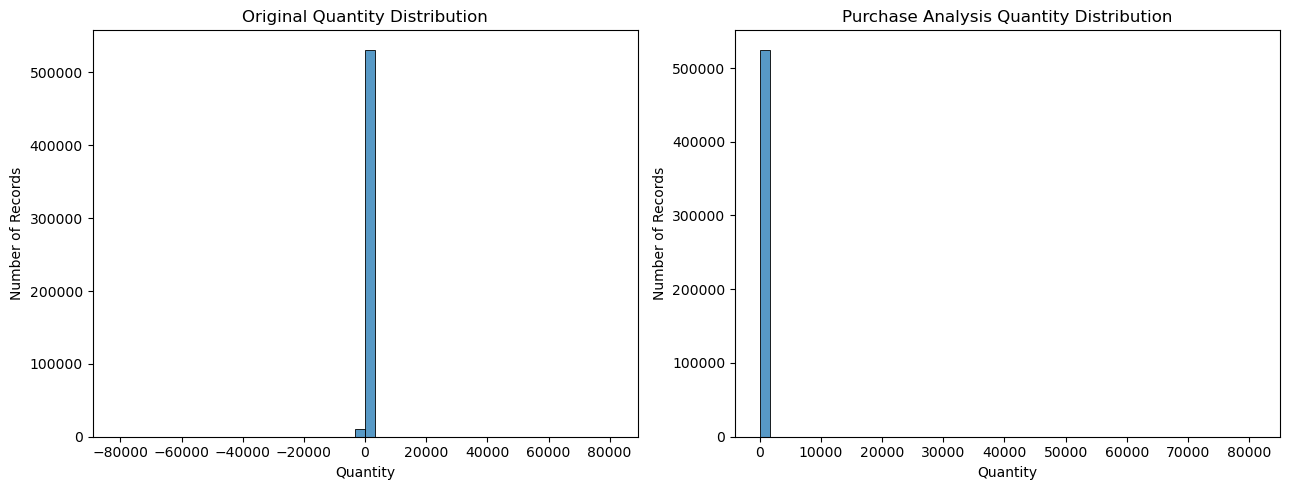

In [59]:

# Create a figure containing two histograms
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot original quantity distribution
sns.histplot(
    data=df,
    x="Quantity",
    bins=50,
    ax=axes[0]
)
axes[0].set_title("Original Quantity Distribution")
axes[0].set_xlabel("Quantity")
axes[0].set_ylabel("Number of Records")

# Plot cleaned purchase quantity distribution
sns.histplot(
    data=df_sales,
    x="Quantity",
    bins=50,
    ax=axes[1]
)
axes[1].set_title("Purchase Analysis Quantity Distribution")
axes[1].set_xlabel("Quantity")
axes[1].set_ylabel("Number of Records")

# Improve spacing and show the figure
plt.tight_layout()
plt.show()


# DOCUMENT EVERY CLEANED DECISION 

In [60]:

# Create a log of the cleaning operations and their purpose
cleaning_log = pd.DataFrame([
    {
        "Step": "Data acquisition",
        "Action": "Loaded public retail dataset",
        "Reason": "Establish the source dataset"
    },
    {
        "Step": "Preserve original",
        "Action": "Created df_clean using df.copy()",
        "Reason": "Keep the source data unchanged"
    },
    {
        "Step": "Text standardization",
        "Action": "Removed leading and trailing spaces",
        "Reason": "Improve consistency in text fields"
    },
    {
        "Step": "Data type correction",
        "Action": "Converted date and numerical columns",
        "Reason": "Enable correct calculations and filtering"
    },
    {
        "Step": "Duplicate handling",
        "Action": "Removed exact duplicate rows",
        "Reason": "Avoid unintended duplicate counting"
    },
    {
        "Step": "Outlier investigation",
        "Action": "Calculated IQR boundaries",
        "Reason": "Identify values requiring review"
    },
    {
        "Step": "Feature engineering",
        "Action": "Calculated LineValue",
        "Reason": "Measure transaction-line value"
    },
    {
        "Step": "Analytical filtering",
        "Action": "Created df_sales",
        "Reason": "Focus on valid-date, positive-price purchases"
    },
    {
        "Step": "Scaling",
        "Action": "Standardized Quantity and UnitPrice",
        "Reason": "Prepare numerical features for modeling"
    }
])

# Display the cleaning log
display(cleaning_log)

# Save the log as a CSV file
cleaning_log.to_csv(
    "online_retail_cleaning_log.csv",
    index=False
)

print("Cleaning log export command completed.")


,Step,Action,Reason
0,Data acquisition,Loaded public retail dataset,Establish the source dataset
1,Preserve original,Created df_clean using df.copy(),Keep the source data unchanged
2,Text standardization,Removed leading and trailing spaces,Improve consistency in text fields
3,Data type correction,Converted date and numerical columns,Enable correct calculations and filtering
4,Duplicate handling,Removed exact duplicate rows,Avoid unintended duplicate counting
5,Outlier investigation,Calculated IQR boundaries,Identify values requiring review
6,Feature engineering,Calculated LineValue,Measure transaction-line value
7,Analytical filtering,Created df_sales,"Focus on valid-date, positive-price purchases"
8,Scaling,Standardized Quantity and UnitPrice,Prepare numerical features for modeling


Cleaning log export command completed.
